In [162]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np
import seaborn as sns

In [163]:
directory = Path("180")

files = sorted(file for file in directory.rglob("*") if file.is_file())
countFiles = 0

print("Files type: ")
for file in files:
    print(file.suffix)
    countFiles += 1

print("Number of files: ", countFiles)



Files type: 
.csv
.csv
.csv
Number of files:  3


The dataset has 3 CSV files, each with a different separator (`,`, `;`, `\t`), so `sep` must be set when loading.

In [164]:
gateways = pd.read_csv('180/gateways.csv', sep=';', on_bad_lines='warn')
readings = pd.read_csv('180/readings.csv', sep = r"\t", on_bad_lines='warn', engine='python')
units = pd.read_csv('180/units.csv', on_bad_lines='warn')



In [165]:
gateways.head()

,depot_id,vendor,modelHardware,id_unit,technician,Lon,gatewayId,address_mac,installDate,ipv4,signal_dbm,lastSeen,Lat,firmware_version
0,52,Pinho Lopes Lda.,GWX-200,1739.0,Irina Leal,-6.34286,GW-00000,c0:f5:84:f8:08:41,2024/06/06,188.32.87.90,-65.2,"10/10/2024, 00:00:00",40.57291,v2.7.0
1,113,Christoph GmbH,GWX-100,103.0,Carminho Fonseca,-6.61695,GW-00001,30:db:d5:75:e1:e2,"12/10/2021, 00:00:00",132.117.107.236,-78.7,2024-04-26,39.47290,v1.2.5
2,112,Rädel Löwer AG,GWX-100,13.0,Dr. Marc Robinson,-7.48817,GW-00002,cd:c6:2c:7f:93:2e,2024-04-21,114.142.159.228,-74.9,04 Nov 2024,39.16074,v1.2.5
3,104,Roy and Sons,NODE-9,1344.0,Ryan Rios,-8.59568,GW-00003,d5:03:c8:7c:50:b4,"12/03/2022, 00:00:00",164.198.143.169,-68.3,25 Jan 2025,39.01984,v1.2.5
4,36,Christoph GmbH,GWX-100,1324.0,César da Neto,-9.18714,GW-00004,93:41:75:8f:f1:d5,15 May 2018,65.233.19.254,-52.2,2024-08-06,39.47786,v1.2.5


In [166]:
readings.head()

,id_unit,cycleTs,currentMotor,dpFilter,oilTemperature,reservoirPressure,pressureOil,rms_vibration,flowmeter,humidity_intake,noiseAmbient,dischargeDewpoint,Failure
0,U00193,"08/27/2023, 06:29:00",4.05968,18.69811,64.86904,8.81915,3.75608,2.42950,27.70488,71.41778,71.88633,15.83173,0
1,U00757,2023/11/13,2.36328,49.17312,51.49558,8.07426,3.30342,4.46937,26.57501,65.59907,69.74589,11.00633,1
2,U01997,2023-11-26,7.33857,11.09040,48.07975,9.78198,4.56246,6.87273,32.19223,79.35666,78.22245,6.20960,0
3,U01633,2023-02-22,5.69969,19.58462,73.09699,9.65227,4.35662,NaN,27.33163,62.12112,72.77351,5.18222,1
4,U00467,"01/23/2023, 03:45:00",3.92084,22.86953,64.31103,8.68221,3.62936,6.36960,29.46377,43.40507,73.24571,6.12806,0


In [167]:
units.head()

,codeFleet,depot_id,hours_service,model_code,line_code,manufacturer,overhaulLast,id_unit,year_commission,region_install,serial_number,ownerOperator,duty_class
0,FA,105,20874.1,XC-7,L6,"Rivers, Welch and Hood","05/06/2023, 00:00:00",1,2019,Christinehaven,AJ-0056-27354,Huhn KGaA,3
1,FA,37,6896.4,XC-7,L4,Walker Ltd,2024-01-15,2,2023,Zerbst,ED-7134-75911,Rädel Löwer AG,heavy
2,FE,36,8193.9,APU-12,L4,Schenk GmbH,2023/01/19,3,2022,Guimarães,AT-0639-19922,Macedo Faria e Filhos,1
3,FB,102,18235.4,APU-20,L6,Silva,2024-03-14,4,2019,Lake Amy,JW-3703-50512,Reinhardt,3
4,FB,11,11350.3,XC-7,L5,Huhn KGaA,2019-05-07,5,2021,Fiães,UC-0462-35464,Leal Freitas S/A,1


In [168]:
units["duty_class"].value_counts()

duty_class
L           253
1           250
light       217
N           170
heavy       163
3           161
med         160
normal      155
2           142
H           138
 L           31
 med         25
 1           24
 heavy       23
 light       22
 N           17
 H           14
 normal      14
 3           12
 2            9
Name: count, dtype: int64

The date attributes (`overhaulLast`, `installDate`, `lastSeen`, `cycleTs`) are stored as text, not `datetime`.
Each of them mixes **4 formats** in roughly equal proportions:
`YYYY-MM-DD`, `YYYY/MM/DD`, `MM/DD/YYYY, hh:mm:ss` and `DD Mon YYYY`.
They will be converted to `datetime` in preprocessing.
duty_class mixes numbers and text (3, heavy).

###  Relationships between files

The files are linked by `id_unit`:

    units ──1:N──► readings
      └────1:1──► gateways

- **units → readings (1:N):** each unit has several readings.
- **units → gateways (1:1):** each unit has one gateway; `depot_id` matches in both files.

**Problems:**
- `id_unit` has a different format in each file (`193`, `193.0`, `U00193`), so it must be normalized.
- 162 readings (IDs U90001–U90497) have no matching unit (orphan records).
- 14,000 of the 16,000 gateways are not linked to any unit.

In [169]:
gateways["id_unit"].head(), readings["id_unit"].head(), units["id_unit"].head()
#data is related with id_unit, this column in both 3 files, the data type of id_unit column in each file is different

(0    1739.0
 1     103.0
 2      13.0
 3    1344.0
 4    1324.0
 Name: id_unit, dtype: float64,
 0    U00193
 1    U00757
 2    U01997
 3    U01633
 4    U00467
 Name: id_unit, dtype: object,
 0    1
 1    2
 2    3
 3    4
 4    5
 Name: id_unit, dtype: int64)

In [170]:
gateways["id_unit"] = gateways["id_unit"].astype("Int64")
units["id_unit"] = units["id_unit"].astype(int)
readings["id_unit"] = readings["id_unit"].astype(str).str.lstrip('U').astype(int)
gateways["id_unit"], readings["id_unit"], units["id_unit"]

(0        1739
 1         103
 2          13
 3        1344
 4        1324
          ... 
 15995    <NA>
 15996    <NA>
 15997    <NA>
 15998    <NA>
 15999    <NA>
 Name: id_unit, Length: 16000, dtype: Int64,
 0         193
 1         757
 2        1997
 3        1633
 4         467
          ... 
 15567    1758
 15568    1552
 15569    1052
 15570    1791
 15571    1290
 Name: id_unit, Length: 15572, dtype: int64,
 0          1
 1          2
 2          3
 3          4
 4          5
         ... 
 1995    1996
 1996    1997
 1997    1998
 1998    1999
 1999    2000
 Name: id_unit, Length: 2000, dtype: int64)

`id_unit` is now an integer in all files (`Int64` in gateways, because it contains 14,000 missing values).

## Structure of the records

In [171]:
gateways.shape, readings.shape, units.shape

((16000, 14), (15572, 13), (2000, 13))

In [172]:
gateways.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   depot_id          16000 non-null  int64  
 1   vendor            16000 non-null  object 
 2   modelHardware     16000 non-null  object 
 3   id_unit           2000 non-null   Int64  
 4   technician        16000 non-null  object 
 5   Lon               16000 non-null  float64
 6   gatewayId         16000 non-null  object 
 7   address_mac       16000 non-null  object 
 8   installDate       16000 non-null  object 
 9   ipv4              16000 non-null  object 
 10  signal_dbm        16000 non-null  float64
 11  lastSeen          16000 non-null  object 
 12  Lat               16000 non-null  float64
 13  firmware_version  16000 non-null  object 
dtypes: Int64(1), float64(3), int64(1), object(9)
memory usage: 1.7+ MB


In [173]:
readings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15572 entries, 0 to 15571
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_unit            15572 non-null  int64  
 1   cycleTs            15572 non-null  object 
 2   currentMotor       15572 non-null  float64
 3   dpFilter           14910 non-null  float64
 4   oilTemperature     15572 non-null  float64
 5   reservoirPressure  15572 non-null  float64
 6   pressureOil        15572 non-null  float64
 7   rms_vibration      14950 non-null  float64
 8   flowmeter          15572 non-null  float64
 9   humidity_intake    14780 non-null  float64
 10  noiseAmbient       15572 non-null  float64
 11  dischargeDewpoint  15572 non-null  float64
 12  Failure            15572 non-null  int64  
dtypes: float64(10), int64(2), object(1)
memory usage: 1.5+ MB


In [174]:
units.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   codeFleet        2000 non-null   object 
 1   depot_id         2000 non-null   int64  
 2   hours_service    1900 non-null   float64
 3   model_code       2000 non-null   object 
 4   line_code        2000 non-null   object 
 5   manufacturer     2000 non-null   object 
 6   overhaulLast     2000 non-null   object 
 7   id_unit          2000 non-null   int64  
 8   year_commission  2000 non-null   int64  
 9   region_install   2000 non-null   object 
 10  serial_number    2000 non-null   object 
 11  ownerOperator    2000 non-null   object 
 12  duty_class       2000 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 203.2+ KB


## Null values and duplicates

In [175]:
readings.isna().sum()

id_unit                0
cycleTs                0
currentMotor           0
dpFilter             662
oilTemperature         0
reservoirPressure      0
pressureOil            0
rms_vibration        622
flowmeter              0
humidity_intake      792
noiseAmbient           0
dischargeDewpoint      0
Failure                0
dtype: int64

In [176]:
gateways.isna().sum()

depot_id                0
vendor                  0
modelHardware           0
id_unit             14000
technician              0
Lon                     0
gatewayId               0
address_mac             0
installDate             0
ipv4                    0
signal_dbm              0
lastSeen                0
Lat                     0
firmware_version        0
dtype: int64

In [177]:
units.isna().sum()

codeFleet            0
depot_id             0
hours_service      100
model_code           0
line_code            0
manufacturer         0
overhaulLast         0
id_unit              0
year_commission      0
region_install       0
serial_number        0
ownerOperator        0
duty_class           0
dtype: int64

In [178]:
gateways.duplicated().sum()

np.int64(0)

In [179]:
readings.duplicated().sum()

np.int64(230)

In [180]:
units.duplicated().sum()

np.int64(0)

`readings` contains 230 exact duplicates, which will be removed in preprocessing.
Missing values in `dpFilter` (662), `rms_vibration` (622), `humidity_intake` (792) and `hours_service` (100)
will be imputed. The 14,000 missing `gateways.id_unit` values are structural (gateways without a unit).

## B. Analysis of individual attributes

We analyze 13 continuous numeric attributes, chosen because they are measured values
whose distribution and valid range can be checked:

- **readings** (sensor measurements): `currentMotor`, `dpFilter`, `oilTemperature`, `reservoirPressure`,
  `pressureOil`, `rms_vibration`, `flowmeter`, `humidity_intake`, `noiseAmbient`, `dischargeDewpoint`
- **gateways** (device location and signal): `Lat`, `Lon`, `signal_dbm`

count       15572.000000
mean            5.296595
std             3.273052
min             0.266600
25%             3.743080
50%             5.087180
75%             6.663353
max            99.000000
skew           19.601706
kurtosis      558.268098
median          5.087180
Name: currentMotor, dtype: float64

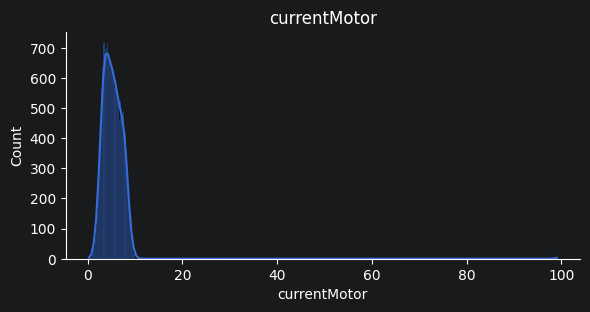

count       14910.000000
mean           24.119032
std            11.502224
min             7.448490
25%            16.329075
50%            21.389575
75%            28.541063
max           120.000000
skew            2.014745
kurtosis        7.194025
median         21.389575
Name: dpFilter, dtype: float64

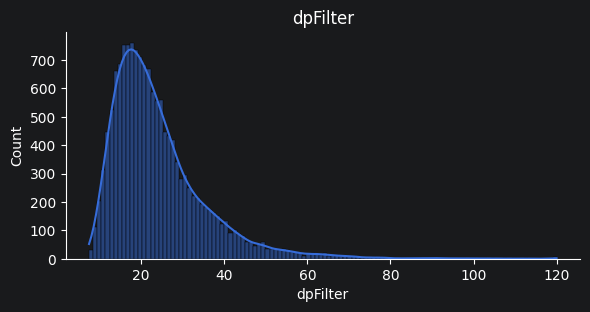

count       15572.000000
mean           51.744591
std            59.647429
min          -999.000000
25%            46.756825
50%            54.967085
75%            63.158803
max            95.000000
skew          -16.847193
kurtosis      293.975859
median         54.967085
Name: oilTemperature, dtype: float64

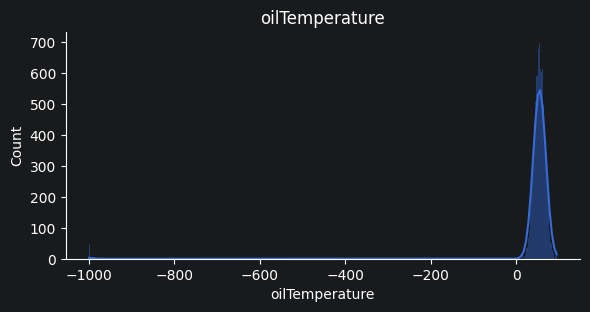

count       15572.000000
mean            8.692845
std             0.598296
min             6.500000
25%             8.285735
50%             8.691360
75%             9.096332
max            10.500000
skew           -0.000892
kurtosis       -0.037602
median          8.691360
Name: reservoirPressure, dtype: float64

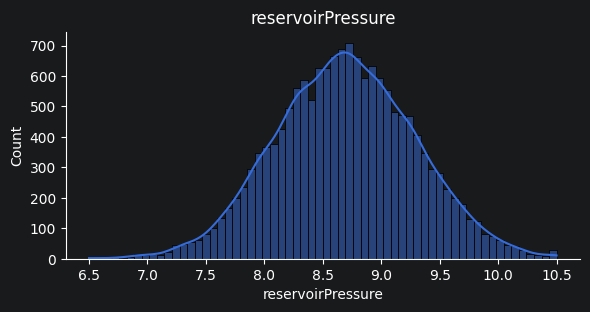

count       15572.000000
mean            3.692293
std             0.561880
min             1.500000
25%             3.311948
50%             3.688170
75%             4.070700
max             5.775210
skew            0.026011
kurtosis       -0.027228
median          3.688170
Name: pressureOil, dtype: float64

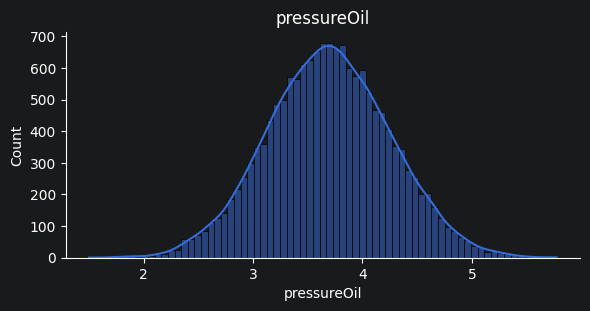

count       14950.000000
mean            3.061109
std             1.628904
min             0.500000
25%             1.925193
50%             2.709255
75%             3.774242
max            14.000000
skew            1.649602
kurtosis        4.473238
median          2.709255
Name: rms_vibration, dtype: float64

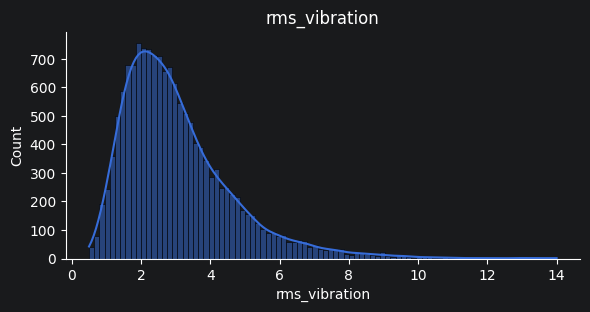

count       15572.000000
mean           28.028240
std             3.956733
min            15.000000
25%            25.348402
50%            28.029065
75%            30.713195
max            40.000000
skew           -0.019540
kurtosis       -0.074550
median         28.029065
Name: flowmeter, dtype: float64

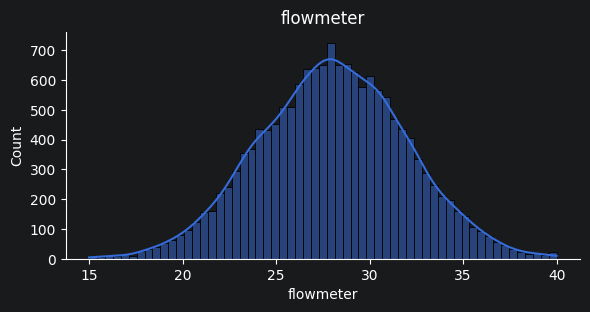

count       14780.000000
mean           52.308947
std            24.458946
min            10.005000
25%            31.194165
50%            52.068300
75%            73.350480
max            94.997260
skew            0.009268
kurtosis       -1.191957
median         52.068300
Name: humidity_intake, dtype: float64

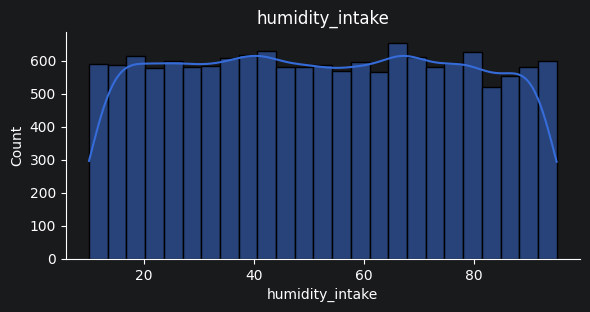

count       15572.000000
mean           74.990066
std             5.994324
min            55.000000
25%            70.977465
50%            74.961685
75%            79.073712
max            95.000000
skew           -0.017156
kurtosis       -0.036102
median         74.961685
Name: noiseAmbient, dtype: float64

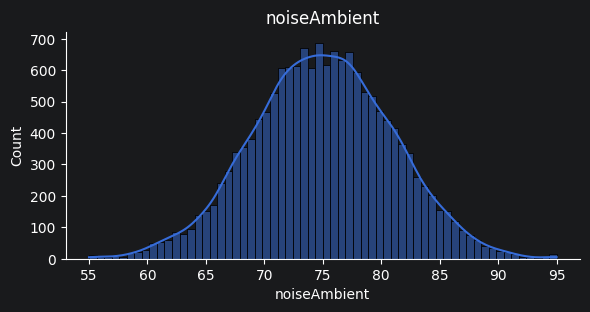

count       15572.000000
mean            8.048645
std             3.502732
min            -4.322190
25%             5.666780
50%             8.013085
75%            10.414853
max            22.421020
skew            0.034431
kurtosis        0.012359
median          8.013085
Name: dischargeDewpoint, dtype: float64

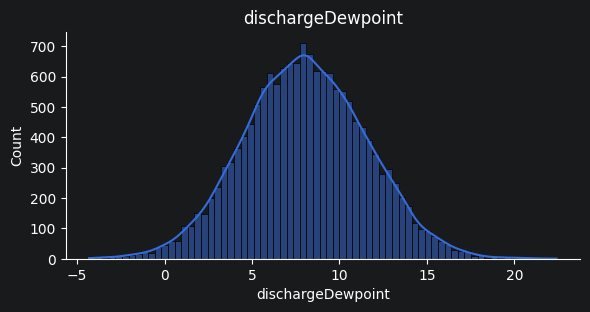

count       16000.000000
mean           40.157236
std             0.889437
min            38.600100
25%            39.390237
50%            40.168405
75%            40.923405
max            41.699630
skew           -0.017412
kurtosis       -1.186647
median         40.168405
Name: Lat, dtype: float64

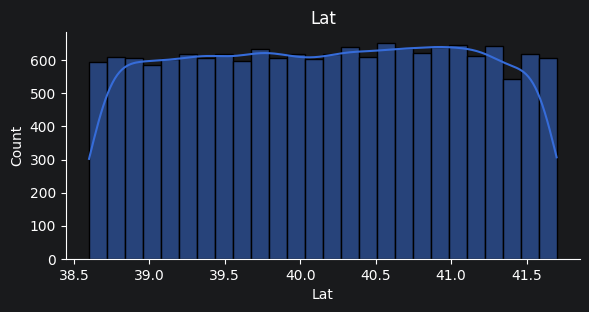

count       16000.000000
mean           -7.747075
std             0.902379
min            -9.299830
25%            -8.534870
50%            -7.737640
75%            -6.963240
max            -6.200030
skew           -0.008257
kurtosis       -1.213274
median         -7.737640
Name: Lon, dtype: float64

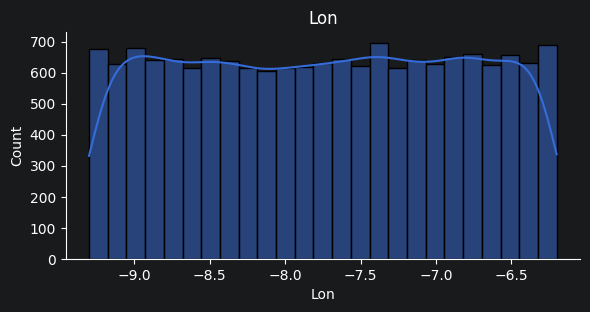

count       16000.000000
mean          -70.009619
std             9.933242
min          -106.100000
25%           -76.700000
50%           -70.200000
75%           -63.100000
max           -40.000000
skew           -0.000390
kurtosis       -0.049539
median        -70.200000
Name: signal_dbm, dtype: float64

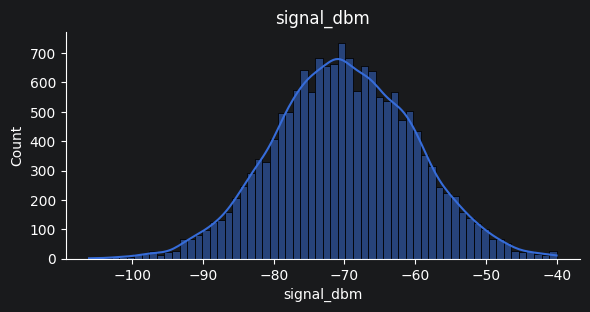

In [181]:
rdngsAtt = ["currentMotor", "dpFilter", "oilTemperature", "reservoirPressure",
  "pressureOil", "rms_vibration", "flowmeter", "humidity_intake", "noiseAmbient", "dischargeDewpoint"]
gtwsAtt = ["Lat", "Lon",
"signal_dbm"]

def attributeDescription(df, attributes):
    for attribute in attributes:
        desc = df[attribute].describe()
        desc["skew"] = df[attribute].skew()
        desc["kurtosis"] = df[attribute].kurtosis()
        desc["median"] = df[attribute].median()

        display(desc)
        sns.displot(df[attribute].dropna(), kde=True, height=3, aspect=2)
        plt.title(attribute)
        plt.show()

attributeDescription(readings, rdngsAtt)
attributeDescription(gateways, gtwsAtt)


**currentMotor** – mean 5.30, median 5.09, std 3.27, range 0.27–99.
Extreme skew (19.6) and kurtosis (558) are caused by 13 values of **99**, a placeholder.
Without them: max 10.0, so a nearly symmetric distribution (skew 0.18)
capped at 10.

**dpFilter** – mean 24.1, median 21.4, std 11.5, range 7.5–120, 662 missing.
**Right-skewed** (skew 2.0, kurtosis 7.2): most values are 15–29 (IQR), with a long tail of high
pressure drops, which indicates clogged filters. The mean is above the median because of the tail.
All values are within the physically plausible range.

**oilTemperature** – mean 51.7, median 55.0, std 59.7, range −999–95.
The statistics are distorted by 48 values of **−999** (placeholder): skew −16.9, std 59.7.
Without them: mean 55.0, median 55.0, std 12.0, skew ≈ 0, a **normal distribution** around 55 °C,
which is a realistic operating temperature for compressor oil.

**reservoirPressure** – mean 8.69, median 8.69, std 0.60, range 6.5–10.5.
**Normal distribution** (skew 0.0, kurtosis 0.0), mean = median. Values are within the physically plausible range;
20 values at exactly 10.5 suggest sensor saturation at the maximum.

**pressureOil** – mean 3.69, median 3.69, std 0.56, range 1.5–5.8.
**Normal distribution** (skew 0.03, kurtosis −0.03), narrow spread. All values are valid.

**rms_vibration** – mean 3.06, median 2.71, std 1.63, range 0.5–14, 622 missing.
**Right-skewed** (skew 1.65, kurtosis 4.5): typical vibration is 2–4 mm/s, but a tail reaches 14 mm/s.
Values above about 11 mm/s count as severe vibration (ISO 10816) and may indicate a failure.

**flowmeter** – mean 28.0, median 28.0, std 3.96, range 15–40.
**Normal distribution** (skew ≈ 0). Values are within the physically plausible range; 19 values at exactly 40
and 9 at 15 indicate sensor limits.

**humidity_intake** – mean 52.3, median 52.1, std 24.5, range 10–95 %, 792 missing.
**Uniform distribution** (kurtosis −1.19, a flat histogram): every humidity level between 10 and
95 % is equally frequent. All values are within the valid range of 0–100 %.

**noiseAmbient** – mean 75.0, median 75.0, std 6.0, range 55–95 dB.
**Normal distribution** (skew ≈ 0), a realistic industrial noise level. 11 values at exactly 95 dB
suggest the sensor's upper limit.

**dischargeDewpoint** – mean 8.05, median 8.01, std 3.50, range −4.3–22.4 °C.
**Normal distribution** (skew 0.03). 163 negative values are physically possible (dried
compressed air), so all values are valid.

**Lat** – mean 40.16, median 40.17, std 0.89, range 38.6–41.7.
**Lon** – mean −7.75, median −7.74, std 0.90, range −9.3 to −6.2.
Both are **uniformly distributed** (kurtosis ≈ −1.2, flat histograms): gateways are spread evenly
over a rectangular area in Portugal. All coordinates are valid.

**signal_dbm** – mean −70.0, median −70.2, std 9.9, range −106 to −40 dBm.
**Normal distribution** (skew 0.0). The values are realistic for a wireless signal; values below
about −100 dBm mean a very weak connection.


## Check for meeting ranges of measured values

In [182]:

def checkMeasuredRanges(df, columns):
    rows = []
    for c in columns:
        s = df[c].dropna()
        lower = s.quantile(.25) - 1.5*stats.iqr(s)
        upper = s.quantile(.75) + 1.5*stats.iqr(s)
        rows.append({
            "attribute":     c,
            "min":           s.min(),
            "max":           s.max(),
            "iqr_outliers":  ((s < lower) | (s > upper)).sum(),
            "count_at_min":  (s == s.min()).sum(),
            "count_at_max":  (s == s.max()).sum(),
        })
    return pd.DataFrame(rows).set_index("attribute")

display(checkMeasuredRanges(readings, rdngsAtt))
display(checkMeasuredRanges(gateways, gtwsAtt))

,min,max,iqr_outliers,count_at_min,count_at_max
attribute,,,,,
currentMotor,0.26660,99.00000,13,1,13
dpFilter,7.44849,120.00000,680,2,6
oilTemperature,-999.00000,95.00000,152,48,7
reservoirPressure,6.50000,10.50000,111,4,20
pressureOil,1.50000,5.77521,102,1,1
rms_vibration,0.50000,14.00000,599,6,4
flowmeter,15.00000,40.00000,105,9,19
humidity_intake,10.00500,94.99726,0,1,1
noiseAmbient,55.00000,95.00000,98,4,11


,min,max,iqr_outliers,count_at_min,count_at_max
attribute,,,,,
Lat,38.60010,41.69963,0,1,1
Lon,-9.29983,-6.20003,0,1,1
signal_dbm,-106.10000,-40.00000,102,1,20


| Attribute | Min | Max | Meets expected range |
|---|---|---|---|
| currentMotor | 0.27 | 99 | ❌ 99 is a placeholder (normal values ≤ 10) |
| dpFilter | 7.45 | 120 | ✅ |
| oilTemperature | −999 | 95 | ❌ −999 °C is impossible (placeholder) |
| reservoirPressure | 6.5 | 10.5 | ✅ |
| pressureOil | 1.5 | 5.78 | ✅ |
| rms_vibration | 0.5 | 14 | ✅ |
| flowmeter | 15 | 40 | ✅ |
| humidity_intake | 10.0 | 95 | ✅ within 0–100 % |
| noiseAmbient | 55 | 95 | ✅ |
| dischargeDewpoint | −4.3 | 22.4 | ✅ negative is possible for dried air |
| Lat | 38.6 | 41.7 | ✅ within ±90°, Portugal |
| Lon | −9.3 | −6.2 | ✅ within ±180°, Portugal |
| signal_dbm | −106 | −40 | ✅ realistic signal |

Expected ranges are based on physical plausibility.
IQR outliers in the valid attributes are real extreme measurements, not errors.
Many identical values at the exact maximum (`count_at_max`, e.g. `reservoirPressure` 10.5,
`flowmeter` 40, `signal_dbm` −40).

**Summary:**
- **Normal distribution:** `reservoirPressure`, `pressureOil`, `flowmeter`, `noiseAmbient`,
  `dischargeDewpoint`, `signal_dbm` (and `oilTemperature` after removing −999).
- **Right-skewed:** `dpFilter`, `rms_vibration`, with long tails of high values that may relate to failures.
- **Uniform:** `humidity_intake`, `Lat`, `Lon`.
- **Invalid values:** −999 in `oilTemperature` (48×) and 99 in `currentMotor` (13×). They are
  placeholders that distort the mean and std and will be replaced with NaN.
